# Taught Preprocessing Techniques and Small-FOD Visibility

This notebook tests selected lecture techniques rather than assuming that every enhancement helps object detection. The analysis asks whether each operation improves or damages evidence associated with small debris.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
TABLE_DIR = PROJECT_ROOT / 'reports/tables/preprocessing'
FIGURE_DIR = PROJECT_ROOT / 'reports/figures/preprocessing'
summary = json.loads((TABLE_DIR / 'preprocessing_summary.json').read_text())
results = pd.read_csv(TABLE_DIR / 'technique_comparison.csv')
print(f"Small objects: {summary['small_objects_in_dataset']:,}")
print(f"Independent sequence-balanced examples: {summary['sequence_balanced_examples']:,}")

Small objects: 9,852
Independent sequence-balanced examples: 74


## 1. Experimental design

FOD-A contains 9,852 COCO-small objects, but many belong to adjacent video frames. To avoid pseudoreplication, the experiment selects one median-sized small object from each sequence containing small FOD. This produces 74 independent sequence-balanced examples spanning Bright–Dry, Dim–Dry, Dark–Dry and Dim–Wet conditions.

Two paired visibility measures are calculated inside each ground-truth box relative to its immediate surroundings:

- **Local contrast-to-noise ratio:** intensity separation between the object and nearby pavement, adjusted for surrounding variation.
- **Object edge energy:** mean Sobel magnitude within the object box.

These are visibility proxies, not detector accuracy.

## 2. Intensity histograms and capture conditions

The publisher's bright, dim and dark labels produce different but overlapping intensity distributions. They are qualitative labels rather than calibrated lux ranges. This overlap argues against a single global brightness threshold.

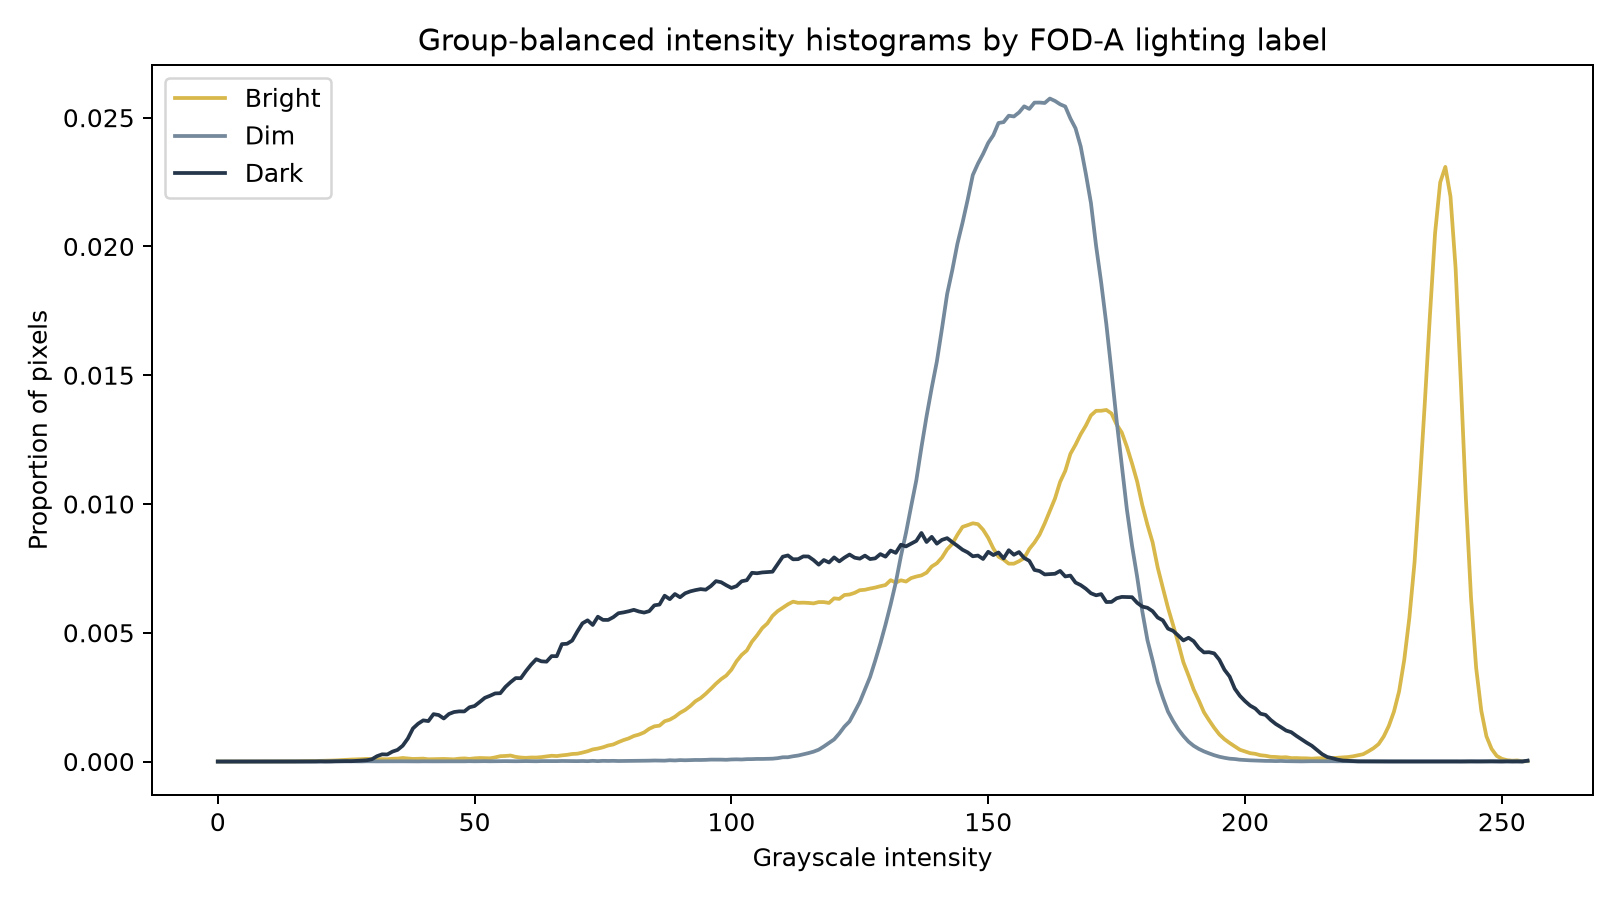

In [2]:
display(Image(filename=FIGURE_DIR / 'intensity_histograms.png'))

## 3. Techniques and fixed parameters

| Technique | Configuration | Role in this analysis |
|---|---|---|
| Contrast stretching | 2nd–98th intensity percentiles mapped to 0–255 | Candidate input enhancement |
| CLAHE | Clip limit 2.0, 8×8 tiles | Candidate local-contrast enhancement |
| Gaussian filtering | 3×3 kernel | Candidate noise-reduction input |
| Median filtering | 3×3 kernel | Candidate edge-preserving noise reduction |
| Sharpening | Moderate 3×3 Laplacian-style kernel | Candidate input enhancement |
| Sobel | 3×3 gradient magnitude | Diagnostic edge visualisation |
| Canny | Image-adaptive thresholds derived from median intensity | Diagnostic edge visualisation |
| Thresholding | Global Otsu threshold | Classical diagnostic baseline |
| Opening and closing | 3×3 morphology kernel | Threshold-mask cleanup diagnostics |

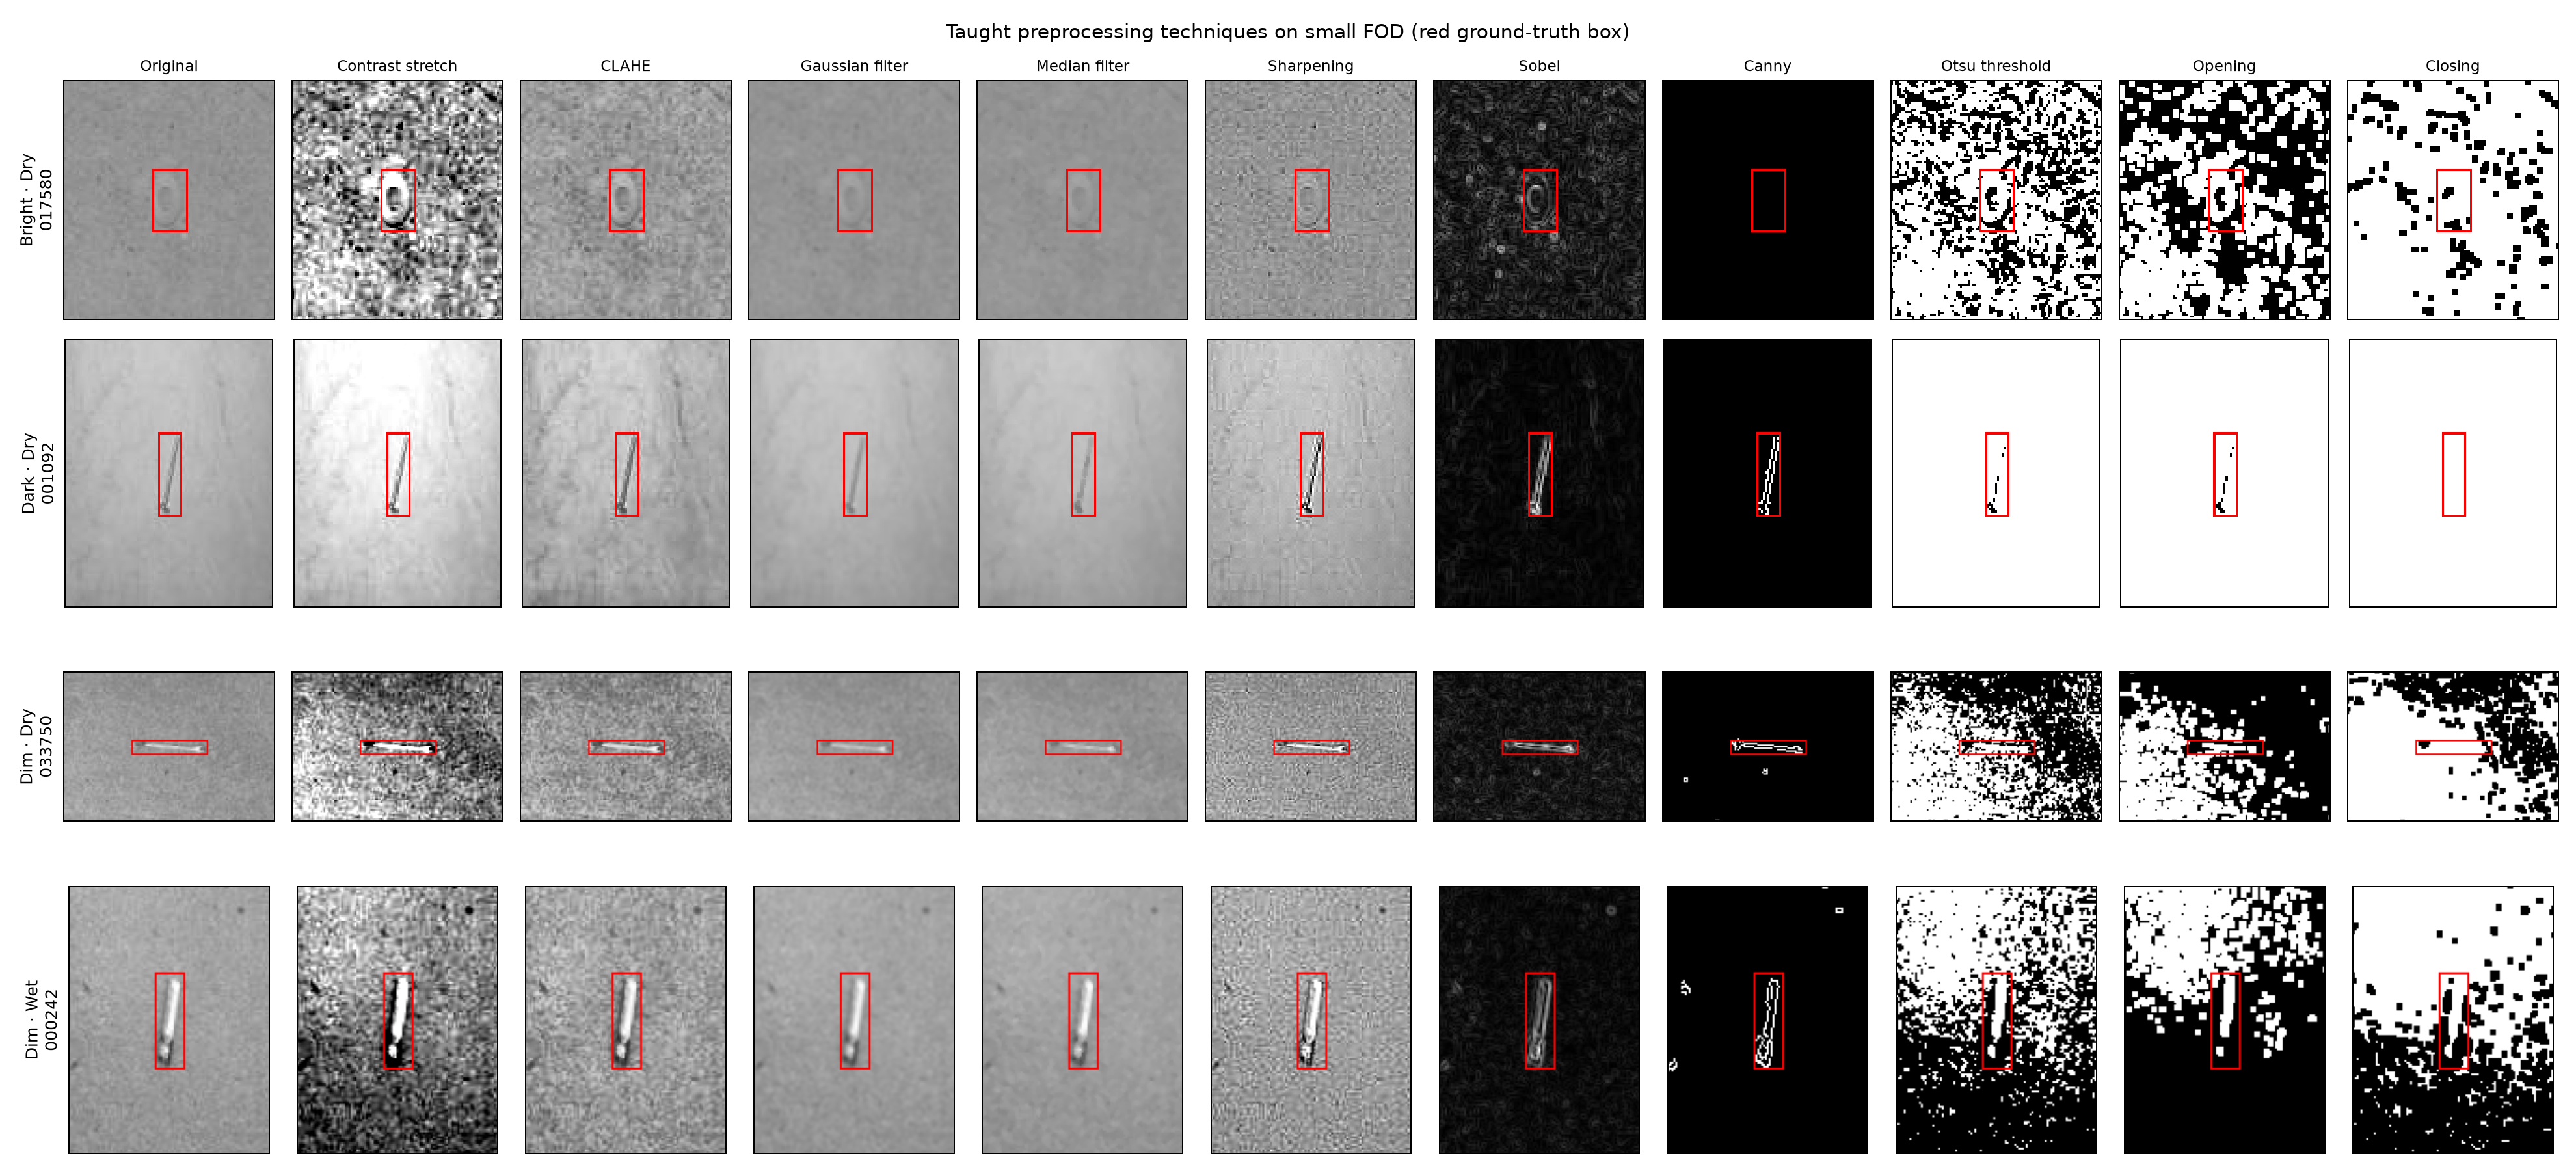

In [3]:
display(Image(filename=FIGURE_DIR / 'technique_comparison_grid.png'))

## 4. Quantitative comparison

Positive contrast change indicates better object-to-background separation. Positive edge change indicates stronger gradients, but can also mean amplified pavement texture or noise. Both signals must therefore be interpreted together.

,technique,median_contrast_change,contrast_improved_percent,median_edge_change,edge_improved_percent,median_background_std_change
0,Original,0.000,0.000,0.000,0.000,0.000
1,Contrast stretch,-0.585,18.919,113.906,90.541,36.230
2,CLAHE,-0.555,22.973,46.731,98.649,8.040
3,Gaussian filter,0.195,93.243,-22.142,0.000,-0.858
4,Median filter,0.199,87.838,-22.005,0.000,-0.887
5,Sharpening,-0.936,6.757,120.965,100.000,6.910


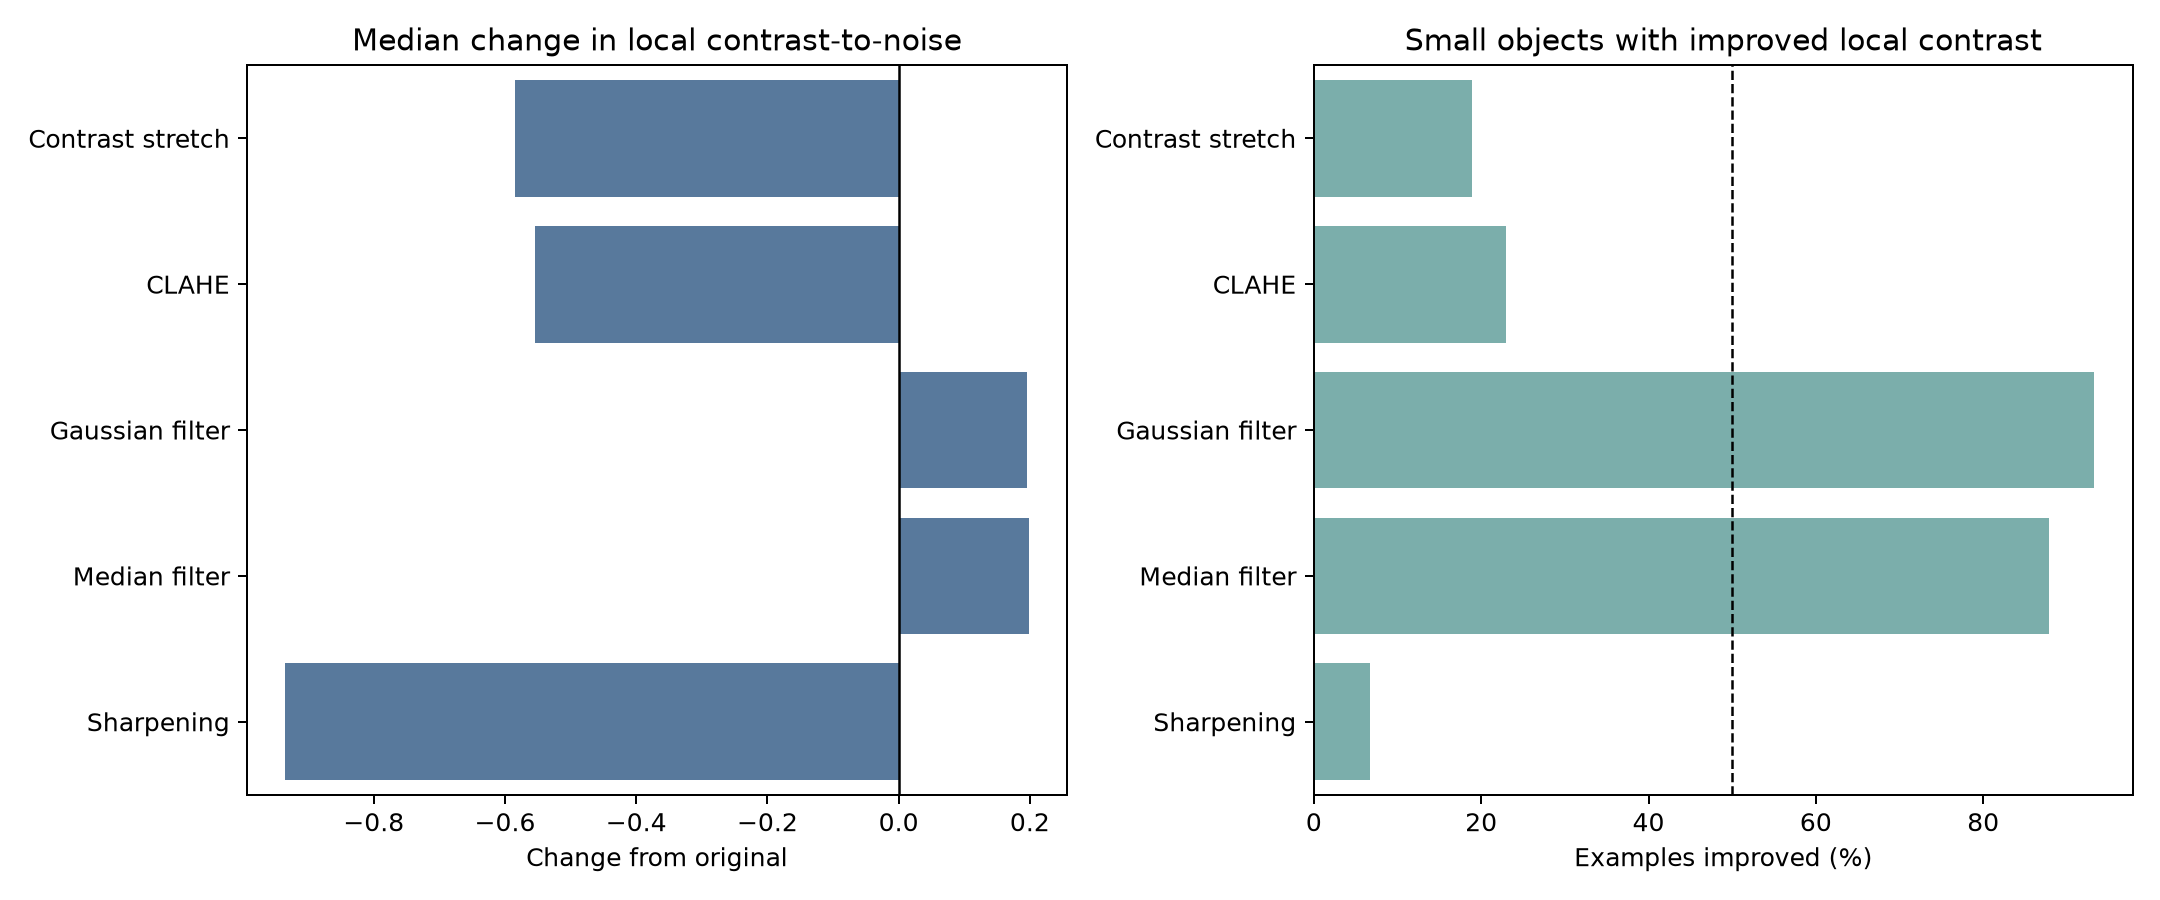

In [4]:
display(results.round(3))
display(Image(filename=FIGURE_DIR / 'visibility_metrics.png'))

## 5. Findings

- **Gaussian filtering** improved the local contrast proxy for 93.2% of sequence-balanced examples, but reduced object edge energy in every case.
- **Median filtering** produced the greatest median contrast improvement and helped 87.8% of examples, but also softened edge evidence in every case.
- **Contrast stretching** strengthened edges for 90.5% of examples but improved local contrast for only 18.9%; the visual grid shows substantial pavement-texture amplification.
- **CLAHE** strengthened edges for 98.6% but improved local contrast for only 23.0%, again increasing background texture.
- **Sharpening** increased edge energy for every example but improved local contrast for only 6.8%, demonstrating that a sharper-looking image is not necessarily a more detectable one.
- **Sobel and Canny** can expose selected debris boundaries, but responses vary greatly and Canny sometimes removes a weak small object completely.
- **Otsu thresholding** frequently segments pavement texture as foreground. Opening can remove small debris together with noise, while closing can merge unrelated regions. These are unsuitable as universal model inputs.

## 6. Decision for modelling

The **original images will be the primary baseline**. Mild Gaussian and median filtering are retained only as controlled preprocessing variants because their contrast improvement is accompanied by edge loss. Contrast stretching, CLAHE and sharpening will not be applied universally based on the current evidence. Sobel, Canny, thresholding and morphology remain diagnostic or classical-baseline techniques rather than deep-model inputs.

This decision is deliberately provisional: visibility proxies cannot establish improved detection. Only a controlled model experiment using the same split, architecture and training settings can determine whether either mild filter improves validation performance, especially recall for small FOD.